# Iris Flower Classification
## Data Preprocessing and Machine Learning Modeling

### 1. Notebook Overview

This notebook focuses on preparing the Iris dataset for machine learning and developing classification models to predict the species of Iris flowers.

It follows the Exploratory Data Analysis (EDA) performed in the previous notebook, where the dataset structure, data quality, statistical characteristics, and relationships between features were investigated.

The dataset contains three Iris flower species:
- Iris-setosa
- Iris-versicolor
- Iris-virginica

Each observation is described by four numerical features:
- Sepal Length
- Sepal Width
- Petal Length
- Petal Width

### Objectives

The main objectives of this notebook are:

1. Load and prepare the Iris dataset.
2. Separate input features (X) from the target variable (y).
3. Split the dataset into training and testing sets.
4. Apply appropriate preprocessing techniques, including feature scaling when necessary.
5. Train different machine learning classification algorithms.
6. Evaluate and compare model performance using appropriate classification metrics.
7. Identify the best-performing model.
8. Test the selected model on new flower measurements.

### Machine Learning Workflow

The notebook follows these main stages:

- Data Loading and Preparation
- Feature and Target Separation
- Train-Test Split
- Feature Scaling
- Model Training
- Model Evaluation
- Model Comparison and Selection
- Final Predictions

### Expected Outcome

By the end of this notebook, we aim to develop a reliable classification model capable of identifying Iris flower species based on their physical measurements.

The final model will be evaluated on unseen test data to assess its ability to generalize to new observations.

## 2. Data Loading and Environment Setup

### Objective

This section prepares the environment for the machine learning workflow.

We import the required Python libraries and load the Iris dataset into a Pandas DataFrame.

The dataset will serve as the input for the preprocessing, training, and evaluation stages.

We also perform a basic verification to ensure that the data has been loaded correctly.

### Step 2.1 — Importing Libraries and Loading the Dataset

We use the following libraries:

- Pandas: for data manipulation and analysis.
- NumPy: for numerical operations.
- Matplotlib and Seaborn: for data visualization.
- Scikit-learn: for data preprocessing, model training, and evaluation.

The dataset is loaded from the CSV file located in the `data` directory.

We then display its first five rows and dimensions to verify the loading process.

In [1]:
# Import data manipulation libraries
import pandas as pd
import numpy as np

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import preprocessing tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Import classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Configure visualization style
sns.set_theme(style="whitegrid")

# Load the Iris dataset
df = pd.read_csv("../data/Iris.csv")

# Verify the dataset
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


## 3. Feature Selection and Target Definition

### Objective

The objective of this section is to identify the input features and the target variable used for the classification task.

The four numerical measurements will be used as input features (X), while the Species column will represent the target variable (y).

The Id column will be excluded because it is only an identifier and does not provide meaningful biological information.

### Step 3.1 — Separating Features and Target

In supervised machine learning, the dataset is divided into two components:

- X (Features): the input variables used by the model to learn patterns.
- y (Target): the output variable that the model must predict.

We select the four numerical flower measurements as features and the Species column as the target.

The Id column is excluded because it does not describe any biological characteristic of the flowers.

In [2]:
# Select the four numerical input features
numerical_features = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

X = df[numerical_features].copy()
y = df["Species"].copy()

# Verify the separation
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
display(X.head())

print("\nTarget variable:")
display(y.head())

Features shape: (150, 4)
Target shape: (150,)

Input features:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target variable:


0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: Species, dtype: str

## 4. Splitting the Dataset into Training and Testing Sets

### Objective

The objective of this section is to divide the dataset into two separate subsets:

- Training set: used to train the machine learning models.
- Testing set: used to evaluate their performance on unseen data.

This separation helps assess the model's ability to generalize to new observations rather than simply memorizing the training data.

### Step 4.1 — Applying Train-Test Split

We use Scikit-learn's `train_test_split()` function to divide the dataset.

The dataset will be split into:

- 80% for training.
- 20% for testing.

We use `random_state=42` to ensure reproducibility.

We also use `stratify=y` to preserve the original class distribution in both subsets.

This is particularly useful for classification problems.

In [3]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the dimensions of each subset
print("Training set:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting set:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Training set:
X_train: (120, 4)
y_train: (120,)

Testing set:
X_test: (30, 4)
y_test: (30,)


### Step 4.2 — Verifying Class Distribution

### Objective

The objective of this step is to verify that the three Iris species are proportionally represented in both the training and testing sets.

We use the `value_counts()` method to count the observations belonging to each species.

This verification confirms that the stratified splitting process has preserved the original class distribution.

We examine the distribution of the target variable in both subsets.

Since the original dataset contains 50 observations for each species, we expect:

- 40 observations per species in the training set.
- 10 observations per species in the testing set.

A balanced distribution helps ensure a fair evaluation of the classification models.

In [4]:
# Check class distribution in the training set
print("Training set class distribution:")
print(y_train.value_counts())

# Check class distribution in the testing set
print("\nTesting set class distribution:")
print(y_test.value_counts())

Training set class distribution:
Species
Iris-setosa        40
Iris-virginica     40
Iris-versicolor    40
Name: count, dtype: int64

Testing set class distribution:
Species
Iris-setosa        10
Iris-virginica     10
Iris-versicolor    10
Name: count, dtype: int64


### Step 4.3 — Train-Test Split Conclusion

The dataset was successfully divided into training and testing sets using an 80/20 split.

The `stratify=y` parameter preserved the original class distribution:

- Training set: 120 observations (40 per species).
- Testing set: 30 observations (10 per species).

The balanced distribution ensures that all three species are represented equally in both subsets.

The training set will be used for model development, while the testing set will remain independent for final performance evaluation.

Stratified cross-validation will also be used during model selection.

## 5. Feature Scaling and Standardization

### Objective

The objective of this section is to standardize the numerical features using Scikit-learn's StandardScaler.

Feature scaling transforms numerical variables to a comparable scale.

This is particularly important for distance-based and optimization-based algorithms, such as K-Nearest Neighbors, Support Vector Machines, and Logistic Regression.

To prevent data leakage, the scaler will be fitted only on the training data and then applied to the testing data.

### Step 5.1 — Applying StandardScaler

StandardScaler transforms each feature by subtracting its mean and dividing by its standard deviation.

The transformation follows:

Z = (X - mean) / standard deviation

The following operations are performed:

1. Initialize the StandardScaler.
2. Fit the scaler on X_train to learn the mean and standard deviation.
3. Transform X_train using the learned parameters.
4. Transform X_test using the same parameters.

The scaler is never fitted on the testing data.

This prevents data leakage and ensures a reliable evaluation.

In [5]:
# Initialize the StandardScaler
scaler = StandardScaler()

# Fit and transform the training features
X_train_scaled = scaler.fit_transform(X_train)

# Transform the testing features using the training parameters
X_test_scaled = scaler.transform(X_test)

# Display the scaled data dimensions
print("Scaled training set:", X_train_scaled.shape)
print("Scaled testing set:", X_test_scaled.shape)

Scaled training set: (120, 4)
Scaled testing set: (30, 4)


In [6]:
# Check the mean and standard deviation of scaled training features
print("Training features means:")
print(X_train_scaled.mean(axis=0))

print("\nTraining features standard deviations:")
print(X_train_scaled.std(axis=0))

Training features means:
[-1.36927506e-16  4.55191440e-16 -9.06682137e-17  5.36607795e-17]

Training features standard deviations:
[1. 1. 1. 1.]


### Step 5.2 — Standardization Verification

The standardization process was successfully completed.

The training features have the following properties:

- Their means are approximately equal to zero.
- Their standard deviations are equal to one.
- The dimensions of the training and testing datasets remain unchanged.

The testing data was transformed using the parameters learned from the training data.

This approach prevents data leakage and ensures consistent preprocessing.

### Conclusion

The numerical features are now standardized and ready for machine learning algorithms that are sensitive to feature scales.

## 6. Preparing Data for Model Training

### Objective

This section organizes the preprocessed training and testing datasets into a consistent format.

The standardized NumPy arrays will be converted into Pandas DataFrames while preserving the original feature names.

This makes the datasets easier to inspect and interpret during model development.

### Step 6.1 — Converting Scaled Arrays into DataFrames

StandardScaler returns NumPy arrays without column names.

We convert these arrays into Pandas DataFrames using the original feature names.

The target variables remain unchanged because they are categorical labels.

This step improves readability and facilitates further analysis.

In [7]:
# Convert standardized arrays into DataFrames
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=numerical_features,
    index=X_train.index
)

X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=numerical_features,
    index=X_test.index
)

# Verify the prepared datasets
print("Training data:")
display(X_train_scaled_df.head())

print("\nTesting data:")
display(X_test_scaled_df.head())

Training data:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
8,-1.721568,-0.324840,-1.347036,-1.320168
106,-1.124492,-1.226129,0.414290,0.651867
76,1.144395,-0.550162,0.584741,0.257460
9,-1.124492,0.125805,-1.290219,-1.451638
89,-0.408002,-1.226129,0.130206,0.125991



Testing data:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
38,-1.721568,-0.099517,-1.403853,-1.320168
127,0.308489,-0.099517,0.641558,0.783336
57,-1.124492,-1.451452,-0.267513,-0.268416
93,-1.005077,-1.676774,-0.267513,-0.268416
42,-1.721568,0.351127,-1.403853,-1.320168


## 7. Model Training

### Objective

In this section, we train multiple machine learning classification algorithms to predict the species of Iris flowers.

The models use four standardized numerical features:

- Sepal Length
- Sepal Width
- Petal Length
- Petal Width

We will train and compare Logistic Regression, K-Nearest Neighbors (KNN), and Random Forest.

The goal is to identify which algorithm provides the best classification performance.

### Step 7.1 — Initializing the Classification Models

We initialize three classification algorithms with their respective parameters.

- Logistic Regression: a linear classification algorithm.
- K-Nearest Neighbors: a distance-based classification algorithm.
- Random Forest: an ensemble learning algorithm based on multiple decision trees.

We use a dictionary to organize the models and facilitate their training and comparison.

In [8]:
# Initialize classification models
models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

print("Classification models initialized:")
for model_name in models:
    print("-", model_name)

Classification models initialized:
- Logistic Regression
- KNN
- Random Forest


### Step 7.2 — Training the Classification Models

In this step, we train each classification model using the standardized training dataset.

The `fit()` method allows each algorithm to learn the relationship between the input features (X_train_scaled) and the target labels (y_train).

Each model learns from the same 120 training observations.

The trained models will then be used to predict the species of flowers in the testing dataset.

In [9]:
# Train each classification model
for model_name, model in models.items():
    model.fit(X_train_scaled, y_train)
    print(f"{model_name} trained successfully.")

Logistic Regression trained successfully.
KNN trained successfully.
Random Forest trained successfully.


### Step 7.3 — Making Predictions

In this step, we use the trained classification models to predict the species of flowers in the testing dataset.

The `predict()` method generates predictions based on the patterns learned during training.

Each model predicts the species of the same 30 unseen observations.

The predicted labels will later be compared with the actual labels (`y_test`) to evaluate model performance.

#### Generating Predictions for Each Model

We apply the `predict()` method to the standardized testing features.

The predictions are stored in a dictionary, with one prediction array for each model.

This organization allows us to compare the predictions of all three algorithms using the same testing observations.

In [10]:
# Generate predictions using each trained model
predictions = {}

for model_name, model in models.items():
    predictions[model_name] = model.predict(X_test_scaled)

    print(f"{model_name} predictions generated successfully.")

# Display the first five predictions of each model
for model_name, y_pred in predictions.items():
    print(f"\n{model_name}:")
    print(y_pred[:5])

Logistic Regression predictions generated successfully.
KNN predictions generated successfully.
Random Forest predictions generated successfully.

Logistic Regression:
['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa']

KNN:
['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa']

Random Forest:
['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa']


## 8. Model Evaluation

### Objective

The objective of this section is to evaluate and compare the performance of the trained classification models on unseen testing data.

We compare predicted species with actual species using classification metrics.

The evaluation includes:

- Accuracy
- Precision
- Recall
- F1-score

This allows us to assess the generalization ability of each model and identify the most promising classifier.

### Step 8.1 — Evaluating Model Accuracy

Accuracy measures the proportion of correctly classified observations among all testing observations.

It is calculated as:

Accuracy = Number of Correct Predictions / Total Number of Predictions

We calculate the accuracy of Logistic Regression, KNN, and Random Forest using the same testing dataset.

Since the dataset contains an equal number of observations for each species, accuracy is a useful initial evaluation metric.

In [11]:
# Calculate accuracy for each model
accuracy_results = {}

for model_name, y_pred in predictions.items():

    accuracy = accuracy_score(y_test, y_pred)

    accuracy_results[model_name] = accuracy

    print(f"{model_name}: {accuracy:.4f} ({accuracy * 100:.2f}%)")

Logistic Regression: 0.9333 (93.33%)
KNN: 0.9333 (93.33%)
Random Forest: 0.9000 (90.00%)


### Step 8.2 — Classification Report

The classification report provides a detailed evaluation of each model's performance for every Iris species.

It includes three important metrics:

- Precision: the proportion of correct positive predictions.
- Recall: the proportion of actual positive observations correctly identified.
- F1-score: the harmonic mean of precision and recall.

The report also provides the support, which represents the number of actual observations belonging to each class.

This analysis helps identify which species are easier or more difficult to classify.

#### Generating Classification Reports

We use Scikit-learn's `classification_report()` function to calculate precision, recall, and F1-score for each species.

The actual labels (`y_test`) are compared with the predictions generated by each trained model.

We use `zero_division=0` to handle any potential division-by-zero cases safely.

In [12]:
# Generate classification reports for all models
for model_name, y_pred in predictions.items():

    print(f"\n{'=' * 60}")
    print(f"Classification Report — {model_name}")
    print('=' * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )


Classification Report — Logistic Regression
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30


Classification Report — KNN
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30


Classification Report — Random Forest
                 precision    recall  f1-score   support

    Iris-setosa       1.0

### Step 8.3 — Confusion Matrix

A confusion matrix provides a detailed comparison between actual and predicted class labels.

It shows:

- True Positives: correctly predicted observations for a given class.
- False Positives: observations incorrectly assigned to a class.
- False Negatives: observations belonging to a class but predicted as another class.

The diagonal cells represent correct predictions, while the off-diagonal cells represent classification errors.

We generate one confusion matrix for each trained model to identify which Iris species are most frequently confused.

#### Generating Confusion Matrices

We use Scikit-learn's `confusion_matrix()` function to compare actual labels with predicted labels.

We visualize each matrix using a Seaborn heatmap.

The same class order is maintained across all models to make comparisons easier.

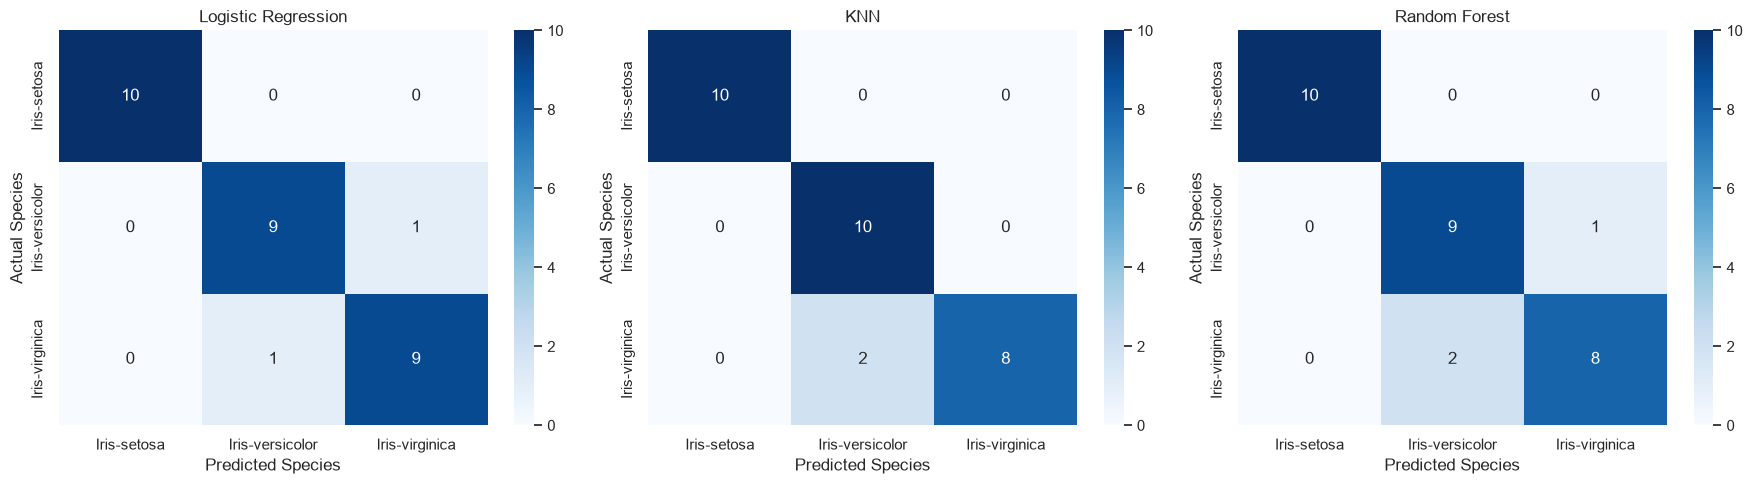

In [13]:
# Define a consistent class order
class_labels = [
    "Iris-setosa",
    "Iris-versicolor",
    "Iris-virginica"
]

# Generate confusion matrices for all models
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, y_pred) in zip(axes, predictions.items()):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")

plt.tight_layout()
plt.show()

### Step 8.4 — Comparing Model Performance

In this step, we compare the performance of the three classification algorithms using multiple evaluation metrics.

We consider:

- Accuracy: Overall proportion of correct predictions.
- Precision: Proportion of correct positive predictions.
- Recall: Proportion of actual positive observations correctly identified.
- F1-score: Harmonic mean of precision and recall.

This comparison helps identify the model offering the best balance between classification performance and reliability.

## 9. Model Comparison

### Objective

The objective of this section is to compare the three trained classification models using Accuracy, Precision, Recall and F1-score.

This comparison will help us identify the most suitable model for Iris flower classification.

In [14]:
# Compare the performance of all classification models

comparison_results = []

for model_name, y_pred in predictions.items():
    report = classification_report(
        y_test,
        y_pred,
        output_dict=True,
        zero_division=0
    )

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": report["macro avg"]["precision"],
        "Recall": report["macro avg"]["recall"],
        "F1-Score": report["macro avg"]["f1-score"]
    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values(
        by="Accuracy",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,KNN,0.9333,0.9444,0.9333,0.9327
2,Random Forest,0.9000,0.9024,0.9000,0.8997


### Step 9.2 — Visualizing Model Performance

We use a grouped bar chart to compare the Accuracy, Precision, Recall and F1-score of the three classification models.

This visualization makes it easier to identify differences in model performance.

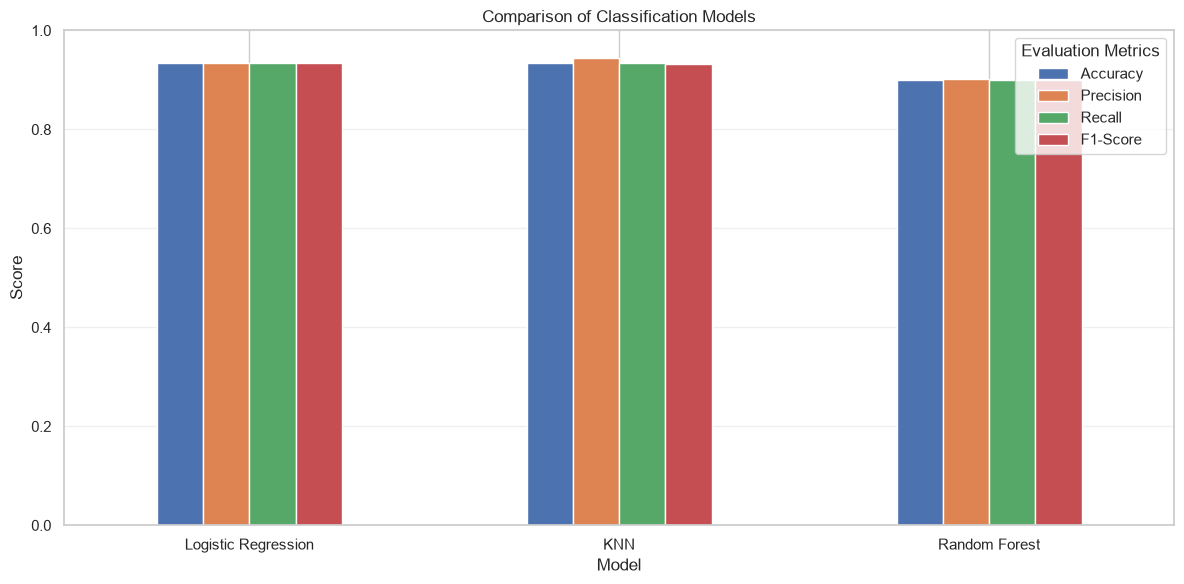

In [15]:
# Visualize model performance comparison

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 10. Hyperparameter Optimization

## Objective

The objective of this section is to improve the performance of the classification models by finding their optimal hyperparameters.

We use GridSearchCV with cross-validation to evaluate different parameter combinations using only the training data.

The best configurations will then be evaluated on the independent test set.

### Step 10.1 — Preparing the Optimization Environment

We import the tools required for hyperparameter optimization.

We use Pipeline to combine feature scaling and classification into a single workflow. This ensures that StandardScaler is fitted separately within each cross-validation fold, preventing data leakage.

In [16]:
# Import optimization and pipeline tools

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Define stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Optimization environment prepared successfully.")
print("Cross-validation: 5 folds")

Optimization environment prepared successfully.
Cross-validation: 5 folds


### Step 10.2 — Defining Hyperparameter Grids

In this step, we define the hyperparameter combinations to explore for each classification algorithm.

- Logistic Regression: regularization strength (C) and solver.
- KNN: number of neighbors, distance metric and weighting strategy.
- Random Forest: number of trees, maximum depth and minimum samples per split.

These combinations will be evaluated using GridSearchCV.

In [20]:
# Define hyperparameter grids for each model

param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__solver": ["lbfgs" ]
    },

    "KNN": {
        "classifier__n_neighbors": [3, 5, 7, 9, 11],
        "classifier__weights": ["uniform", "distance"],
        "classifier__p": [1, 2]
    },

    "Random Forest": {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [None, 5, 10, 20],
        "classifier__min_samples_split": [2, 5, 10]
    }
}

print("Hyperparameter grids defined successfully.")

for model_name, grid in param_grids.items():
    print(f"{model_name}: {len(list(__import__('sklearn').model_selection.ParameterGrid(grid)))} combinations")

Hyperparameter grids defined successfully.
Logistic Regression: 5 combinations
KNN: 20 combinations
Random Forest: 36 combinations


### Step 10.3 — Running GridSearchCV

We create a separate pipeline for each classification algorithm.

Each pipeline combines StandardScaler with the corresponding classifier.

GridSearchCV evaluates all defined hyperparameter combinations using 5-fold stratified cross-validation.

We use macro F1-score as the optimization metric to give equal importance to all three Iris species. 


In [21]:
# Import classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Define classifiers
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(
        random_state=42
    )
}

# Store optimization results
grid_search_results = {}

# Run GridSearchCV for each model
for model_name, classifier in classifiers.items():

    print(f"\nOptimizing {model_name}...")

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", classifier)
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[model_name],
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    grid_search.fit(X_train, y_train)

    grid_search_results[model_name] = grid_search

    print("Best parameters:", grid_search.best_params_)
    print("Best cross-validation F1-score:", round(grid_search.best_score_, 4))

print("\nAll models optimized successfully.")


Optimizing Logistic Regression...
Best parameters: {'classifier__C': 10, 'classifier__solver': 'lbfgs'}
Best cross-validation F1-score: 0.9663

Optimizing KNN...
Best parameters: {'classifier__n_neighbors': 3, 'classifier__p': 2, 'classifier__weights': 'uniform'}
Best cross-validation F1-score: 0.9665

Optimizing Random Forest...
Best parameters: {'classifier__max_depth': None, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}
Best cross-validation F1-score: 0.958

All models optimized successfully.


## Step 10.4 — Evaluating Optimized Models on the Test Set

In this step, we evaluate the optimized classification models using the independent testing set.

We use the best estimators selected by GridSearchCV to generate predictions and calculate their accuracy, precision, recall, and F1-score.

The testing set remains untouched during hyperparameter optimization, providing an unbiased final evaluation of model performance.

In [22]:
# Evaluate optimized models on the independent test set

optimized_results = {}
optimized_predictions = {}

for model_name, grid_search in grid_search_results.items():

    # Retrieve the best optimized pipeline
    best_model = grid_search.best_estimator_

    # Generate predictions on the test set
    y_pred = best_model.predict(X_test)

    optimized_predictions[model_name] = y_pred

    # Calculate evaluation metrics
    report = classification_report(
        y_test,
        y_pred,
        output_dict=True,
        zero_division=0
    )

    optimized_results[model_name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": report["macro avg"]["precision"],
        "Recall": report["macro avg"]["recall"],
        "F1-Score": report["macro avg"]["f1-score"]
    }

# Display the comparison
optimized_comparison = pd.DataFrame(optimized_results).T

display(
    optimized_comparison
    .sort_values(by="F1-Score", ascending=False)
    .round(4)
)

,Accuracy,Precision,Recall,F1-Score
Logistic Regression,1.0000,1.0000,1.0000,1.0000
Random Forest,0.9667,0.9697,0.9667,0.9666
KNN,0.9333,0.9444,0.9333,0.9327


## Step 10.5 — Interpreting the Optimization Results

The optimized Logistic Regression model achieved the best performance on the independent test set, with an accuracy and macro F1-score of 100%.

Random Forest achieved an accuracy of 96.67%, while KNN achieved 93.33%.

These results indicate that Logistic Regression is the strongest candidate among the three optimized models for this dataset.

However, the perfect test score should be interpreted with caution because the test set contains only 30 observations. Further validation on unseen data would be necessary to assess generalization performance.

## Step 10.6 — Confusion Matrix of the Optimized Logistic Regression

In this step, we visualize the confusion matrix of the optimized Logistic Regression model on the independent test set.

The confusion matrix helps us identify the number of correctly and incorrectly classified observations for each Iris species.

This visualization provides a detailed view of the model's classification performance.

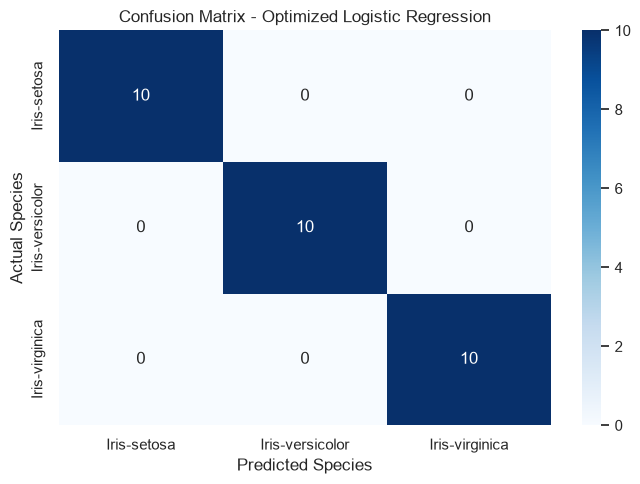

In [23]:
# Retrieve the optimized Logistic Regression model
best_logistic_model = grid_search_results["Logistic Regression"].best_estimator_

# Generate predictions
y_pred_logistic = best_logistic_model.predict(X_test)

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred_logistic, labels=best_logistic_model.classes_)

# Visualize the confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=best_logistic_model.classes_,
    yticklabels=best_logistic_model.classes_
)

plt.title("Confusion Matrix - Optimized Logistic Regression")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

## Step 10.7 — Comparing Model Performance Before and After Optimization

In this step, we compare the performance of the original classification models with their optimized versions.

This comparison helps us understand the impact of hyperparameter tuning on model performance.

We use the same independent testing set and evaluation metrics to ensure a fair comparison.

In [24]:
# Compare original and optimized model performance

comparison_before_after = pd.DataFrame({
    "Model": list(accuracy_results.keys()),
    "Accuracy Before": list(accuracy_results.values()),
    "Accuracy After": [
        optimized_results[name]["Accuracy"]
        for name in accuracy_results.keys()
    ]
})

comparison_before_after["Improvement"] = (
    comparison_before_after["Accuracy After"]
    - comparison_before_after["Accuracy Before"]
)

display(comparison_before_after.round(4))

,Model,Accuracy Before,Accuracy After,Improvement
0,Logistic Regression,0.9333,1.0000,0.0667
1,KNN,0.9333,0.9333,0.0000
2,Random Forest,0.9000,0.9667,0.0667


### Optimization Results — Key Findings

Hyperparameter optimization improved the performance of Logistic Regression and Random Forest, while KNN maintained the same accuracy.

Logistic Regression achieved the best test performance, with 100% accuracy, precision, recall, and F1-score.

Random Forest also improved from 90% to 96.67% accuracy.

These findings demonstrate that hyperparameter tuning can improve model performance, although its impact depends on the algorithm.

Logistic Regression is selected as the best-performing model for this experiment. However, its perfect test score should be interpreted cautiously due to the limited size of the test set.

## 11. Model Deployment Preparation

### Step 11.1 — Saving the Best Optimized Model

In this step, we save the best-performing optimized classification model.

Saving the model allows us to reuse it later for predictions without repeating the training and hyperparameter optimization process.

We use Joblib to serialize the trained model and store it in the project directory.

In [25]:
import os
import joblib

# Retrieve the best optimized Logistic Regression model
best_model = grid_search_results["Logistic Regression"].best_estimator_

# Create the models directory if it does not exist
os.makedirs("../models", exist_ok=True)

# Save the optimized model
model_path = "../models/best_iris_model.joblib"

joblib.dump(best_model, model_path)

print("Model saved successfully!")
print(f"Model location: {model_path}")

Model saved successfully!
Model location: ../models/best_iris_model.joblib


### Step 11.2 — Testing the Saved Model on New Data

In this step, we reload the saved model and use it to classify a new Iris flower based on its four measurements.

This test demonstrates that the saved model can be reused for predictions without retraining.

In [26]:
# Load the saved model
loaded_model = joblib.load(model_path)

# Define a new Iris flower
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X_train.columns
)

# Predict the species
prediction = loaded_model.predict(new_flower)

print("Predicted Iris species:", prediction[0])

Predicted Iris species: Iris-setosa


### Step 11.3 — Testing Multiple New Flower Samples

In this step, we test the saved classification model using multiple flower measurements.

This allows us to verify that the model can predict different Iris species from new input observations.

In [27]:
# Define multiple new Iris flower samples
new_flowers = pd.DataFrame(
    [
        [5.1, 3.5, 1.4, 0.2],
        [6.0, 2.9, 4.5, 1.5],
        [6.5, 3.0, 5.8, 2.2]
    ],
    columns=X_train.columns
)

# Predict the species
predictions = loaded_model.predict(new_flowers)

# Display the results
results = new_flowers.copy()
results["Predicted Species"] = predictions

display(results)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Predicted Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,6.0,2.9,4.5,1.5,Iris-versicolor
2,6.5,3.0,5.8,2.2,Iris-virginica


## 12. Conclusion

This project aimed to classify Iris flowers into three species: Setosa, Versicolor, and Virginica, using machine learning techniques.

Three classification algorithms were evaluated: Logistic Regression, K-Nearest Neighbors (KNN), and Random Forest.

Hyperparameter optimization using GridSearchCV and stratified 5-fold cross-validation improved the performance of Logistic Regression and Random Forest. The optimized Logistic Regression achieved the best test accuracy of 100% on the selected test set.

The final model was saved using Joblib and successfully tested on new flower measurements.

This project demonstrates the complete machine learning workflow, from exploratory data analysis and preprocessing to model evaluation, hyperparameter tuning, and model deployment.

**Future improvements:** Evaluate the model on additional unseen data and explore more advanced validation strategies to assess its generalization performance.